<a href="https://colab.research.google.com/github/u-hihi/IP2026/blob/main/ch04_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt
drive.mount('/content/gdrive')

Mounted at /content/gdrive


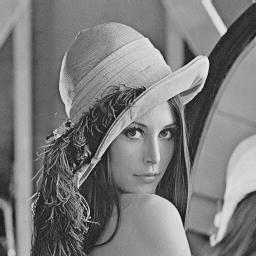

In [3]:
img = cv2.imread('/content/gdrive/My Drive/ColabDIP/images/Images/lena256.jpg')
#img = cv2.imread('/content/gdrive/My Drive/ColabDIP/images/Images/milkdrop.bmp')
#img = cv2.imread('/content/gdrive/My Drive/ColabDIP/images/Images/cell-bright.bmp')
gimg = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
RGB_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

cv2_imshow(gimg)
plt.show()

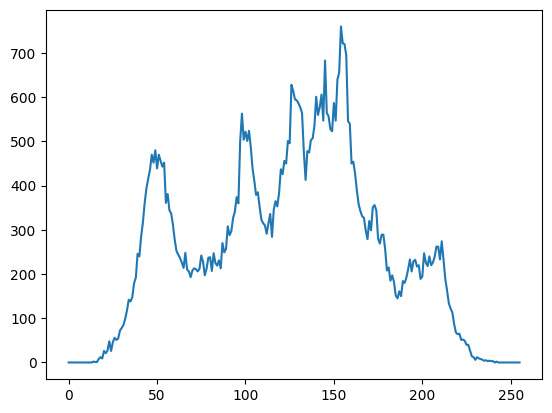

In [4]:
hist=cv2.calcHist([gimg],[0],None,[256],[0,256])
plt.plot(hist)
plt.show()

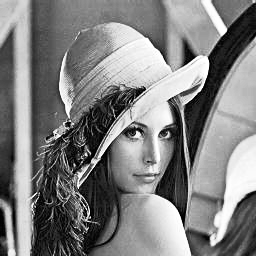

In [5]:
gOut=cv2.equalizeHist(gimg)
cv2_imshow(gOut)
plt.show()

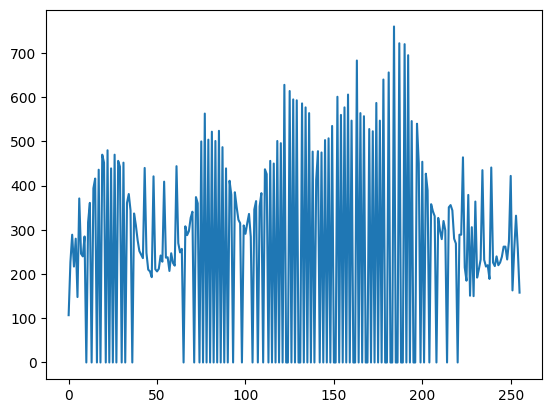

In [6]:
hist2=cv2.calcHist([gOut],[0],None,[256],[0,256])
plt.plot(hist2)
plt.show()

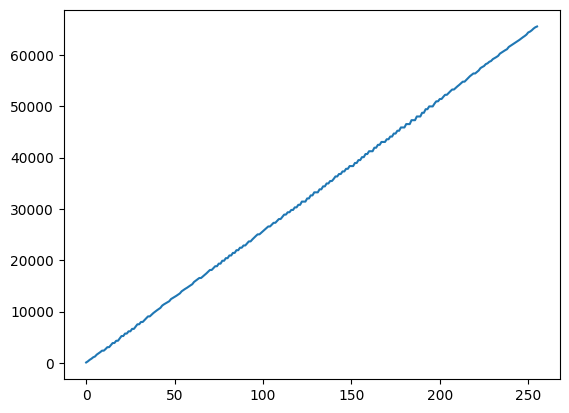

In [7]:
cumlHist= hist2.copy()
for i in range(1,len(cumlHist)):
  cumlHist[i]=cumlHist[i-1]+ hist2[i]

plt.plot(cumlHist)
plt.show()

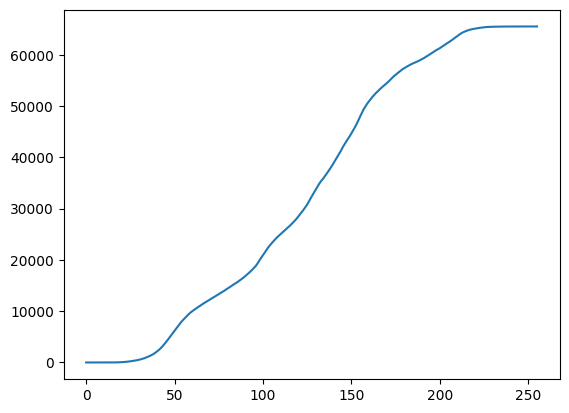

In [8]:
#누적
eqHist = hist.copy()

for i in range(len(eqHist)):
  eqHist[i] = eqHist[i-1] + hist[i]

plt.plot(eqHist)
plt.show()

65536


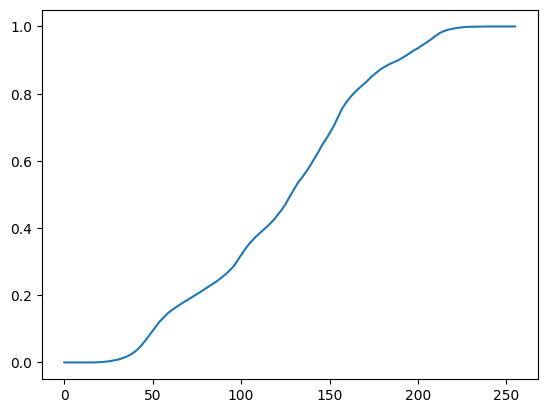

In [10]:
numOfPixels = np.int32(gimg.shape[0]*gimg.shape[1])
print(numOfPixels)
eqHist1 = eqHist / numOfPixels
plt.plot(eqHist1)

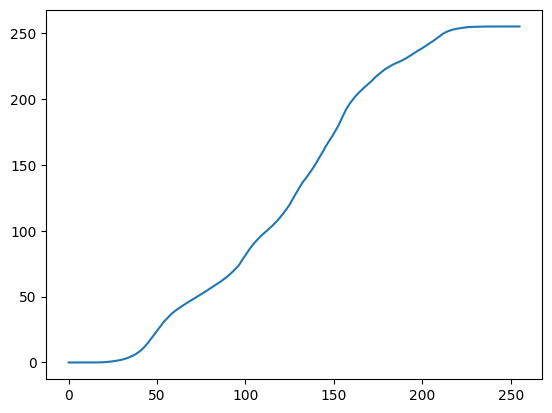

In [11]:
eqHist2 = eqHist1 * 255
plt.plot(eqHist2)

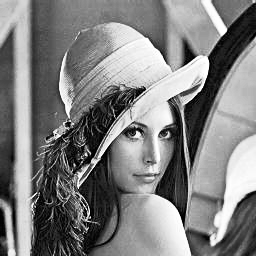

In [12]:
gOut1 = gimg.copy()
for i in range(gimg.shape[0]):
  for j in range(gimg.shape[1]):
    gOut1[i,j] = eqHist2[gimg[i,j]]

cv2_imshow(gOut1)
plt.show()

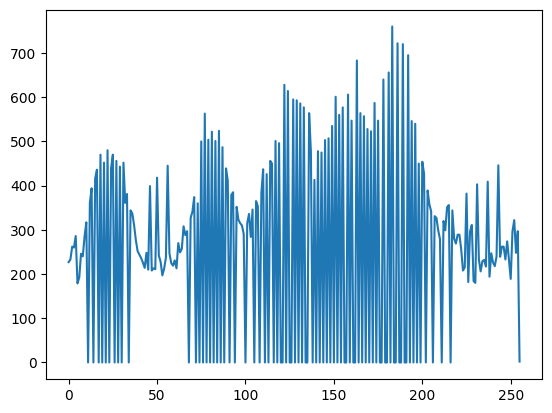

In [14]:
hist3 = cv2.calcHist([gOut1],[0],None,[256],[0,256])
plt.plot(hist3)
plt.show()